# Bounded polynomial weighting of regression errors

Use the exact training weights $w(y)=1+\lambda(1+y/100)^p$, with grade $y\in[0,100]$. The current setting is **λ = 1, p = −2**. This negative exponent emphasizes lower grades: weights decrease from 2 at grade 0 to 1.25 at grade 100. Positive exponents emphasize higher grades. The previous p = 2 run is preserved in its own results directory. The target and previous-year grade stay on their original scales.

For λ ≥ 0 and finite p the weights are bounded by $1+\lambda\min(1,2^p)$ and $1+\lambda\max(1,2^p)$. We pass **raw weights without normalization** to each model; their absolute scale can affect regularization. Squared-error models minimize a weighted squared loss (or their library's normalized equivalent); this does not enforce bounded predictions.

Compare eight models over the same 20 paired 85/15 splits, using four parallel workers. Baseline and inverse-density runs are reused from the earlier experiment when cached. k-NN is omitted because it does not support training sample weights. Classification is omitted; grade bands are used only to inspect regression errors. Hyperparameters are selected by ordinary, unweighted CV RMSE. Test RMSE, MAE and band errors are also unweighted. Parameters are fixed before evaluating the test sets, rather than selected using test results.

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import display, Markdown

# Identical complete-case cohort and income preprocessing to the earlier experiment.
df = pd.read_csv('student_grade_ses_dataset.csv').drop_duplicates().set_index('student_id').dropna()
df['log_income'] = np.log(df.pop('annual_family_income_inr'))
# Schema Setup 

REGRESSION_TARGET     = 'final_grade_pct'
CLASSIFICATION_TARGET = 'grade_class'

CONTINUOUS_COLS = [
    'distance_to_school_km', 
    'study_hours_per_week', 
    'attendance_rate_pct',          
    'previous_year_grade_pct', 
    'log_income'
]

# Integer-coded, including 0/1 flags and the 1-5 parental involvement score
DISCRETE_COLS = [
    'age', 
    'grade_level', 
    'family_size', 
    'num_siblings', 
    'single_parent_household',
    'has_internet_access', 
    'has_computer_or_laptop', 
    'extra_tutoring',
    'parental_involvement_score'
]

# Text labels
CATEGORICAL_COLS = [
    'academic_year', 
    'gender', 
    'school_type', 
    'residence_type', 
    'family_income_bracket',
    'father_education_level', 
    'mother_education_level', 
    'father_occupation',
    'mother_occupation', 
    'scholarship_status'
]

NUMERIC_COLS = CONTINUOUS_COLS + DISCRETE_COLS
PREDICTOR_COLS = NUMERIC_COLS + CATEGORICAL_COLS
# Drop one predictor from each highly correlated pair
# age vs grade_level (r = 0.93) -> keep grade_level
# family_size vs num_siblings (r = 0.94) -> keep family_size
DROP_COLS = ['age', 'num_siblings']

DISCRETE_COLS = [c for c in DISCRETE_COLS if c not in DROP_COLS]
NUMERIC_COLS = CONTINUOUS_COLS + DISCRETE_COLS
PREDICTOR_COLS = NUMERIC_COLS + CATEGORICAL_COLS

X                = df[PREDICTOR_COLS]         # Shared predictors
Y_regression     = df[REGRESSION_TARGET]      # Numeric final grade
Y_classification = df[CLASSIFICATION_TARGET]  # Grade band
print('Dropped:', DROP_COLS)
print('X:', X.shape)
from polynomial_experiment import ONEHOT_COLUMNS, ORDINAL_COLUMNS
schema = {key: globals()[key] for key in [
    'CONTINUOUS_COLS', 'NUMERIC_COLS', 'PREDICTOR_COLS', 'ONEHOT_COLUMNS', 'ORDINAL_COLUMNS']}
assert np.isfinite(X['previous_year_grade_pct']).all()
assert X['previous_year_grade_pct'].between(0, 100).all()
assert Y_regression.between(0, 100).all()
print(f'{len(X):,} students; {len(X.columns)} predictors')

Dropped: ['age', 'num_siblings']
X: (8785, 22)


8,785 students; 22 predictors


## Adjustable parameters and weight direction
Change `WEIGHT_CONFIG` below to add another run. Changed parameters get a separate checkpoint directory. This first plot uses only split 0's training grades; actual model fits compute weights from their own training targets.

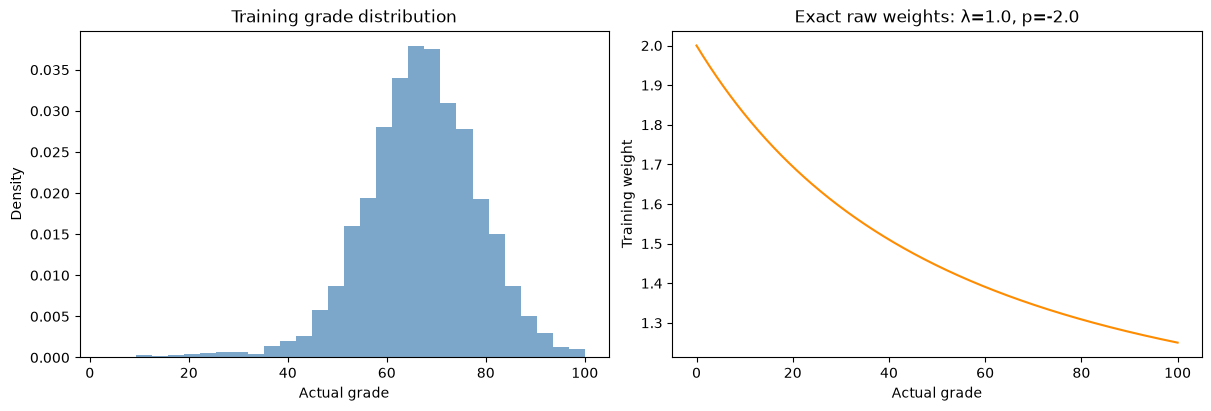

,count,mean_weight,min_weight,max_weight
grade band,,,,
A,134,1.266219,1.250000,1.277008
B,1639,1.308336,1.277300,1.326531
C,3871,1.357777,1.326904,1.390625
D,1686,1.423603,1.391114,1.510204
F,137,1.605658,1.510934,1.946267


Weight at 0 and 100: [2.   1.25]


In [2]:
from polynomial_experiment import polynomial_weights, NAMES, GRIDS, run_experiments
from sklearn.model_selection import train_test_split
WEIGHT_CONFIG = dict(lam=1.0, power=-2.0)
NUMBER_OF_EXPERIMENTS = 20
N_JOBS = 4
SMOKE = False
CONDITIONS = ['Baseline', 'Polynomial weighted', 'Density weighted']
_, _, inspect_y, _ = train_test_split(X, Y_regression, test_size=.15, random_state=0)
grade_grid = np.linspace(0,100,501)
weights = polynomial_weights(inspect_y, **WEIGHT_CONFIG)
fig, axes = plt.subplots(1,2,figsize=(12,4),layout='constrained')
axes[0].hist(inspect_y, bins=30, density=True, color='steelblue', alpha=.7)
axes[0].set(title='Training grade distribution', xlabel='Actual grade', ylabel='Density')
axes[1].plot(grade_grid,polynomial_weights(grade_grid, **WEIGHT_CONFIG),color='darkorange')
axes[1].set(title=f'Exact raw weights: λ={WEIGHT_CONFIG["lam"]}, p={WEIGHT_CONFIG["power"]}',xlabel='Actual grade',ylabel='Training weight')
plt.show()
weight_summary = pd.DataFrame({'grade':inspect_y,'weight':weights,'grade band':df.loc[inspect_y.index, CLASSIFICATION_TARGET]})
display(weight_summary.groupby('grade band').agg(count=('weight','size'),mean_weight=('weight','mean'),min_weight=('weight','min'),max_weight=('weight','max')))
print('Weight at 0 and 100:',polynomial_weights([0,100], **WEIGHT_CONFIG))

## Paired experiments
All three conditions use identical held-out students, preprocessing and model grids. Polynomial weights are applied separately in each training fold. No transformation or resampling is applied. The previous inverse-density reference uses training-fold KDE weights with its original normalization and cap settings; it therefore changes both weight shape and scale relative to polynomial weighting.

In [3]:
import time, json, platform, importlib.metadata
import density_experiment as density_reference
start = time.perf_counter()
reference_results, reference_directory = density_reference.run_experiments(
    X,Y_regression,df[CLASSIFICATION_TARGET],schema,n_splits=NUMBER_OF_EXPERIMENTS,n_jobs=N_JOBS,smoke=SMOKE)
results, result_directory = run_experiments(
    X,Y_regression,df[CLASSIFICATION_TARGET],schema,n_splits=NUMBER_OF_EXPERIMENTS,n_jobs=N_JOBS,
    smoke=SMOKE,weight_config=WEIGHT_CONFIG)
elapsed_seconds = time.perf_counter()-start
all_results = reference_results + results
all_predictions = pd.concat([p for r in all_results for p in r['predictions']],ignore_index=True)
all_metrics = pd.DataFrame([p for r in all_results for p in r['metrics']])
all_timings = pd.DataFrame([p for r in all_results for p in r['timings']])
# Pair each model/condition by the held-out student, not just row position.
assert not all_predictions.duplicated(['experiment','model','condition','student_id']).any()
for _, group in all_predictions.groupby(['experiment','model']):
    baseline = group[group.condition.eq('Baseline')].set_index('student_id').sort_index()
    for condition in CONDITIONS[1:]:
        current = group[group.condition.eq(condition)].set_index('student_id').sort_index()
        pd.testing.assert_frame_equal(current[['actual','grade band']],baseline[['actual','grade band']])
assert np.isfinite(all_predictions.predicted).all()
all_predictions['absolute error'] = (all_predictions.predicted-all_predictions.actual).abs()
all_predictions['overprediction'] = all_predictions.predicted-all_predictions.actual
f_metrics = (all_predictions[all_predictions['grade band'].eq('F')]
    .groupby(['experiment','condition','model']).agg(**{'F MAE':('absolute error','mean'),
        'F overprediction':('overprediction','mean'),'F support':('actual','size')}).reset_index())
comparison = all_metrics.merge(f_metrics,on=['experiment','condition','model'],how='left')
comparison['F support'] = comparison['F support'].fillna(0).astype(int)
for label, frame in [('predictions',all_predictions),('metrics',all_metrics),('timings',all_timings),('comparison',comparison)]:
    frame.to_csv(result_directory/(label+'.csv'),index=False)
manifest = dict(python=platform.python_version(),versions={p:importlib.metadata.version(p) for p in ['numpy','pandas','scikit-learn','pygam','joblib']},
    splits=NUMBER_OF_EXPERIMENTS,workers=N_JOBS,smoke=SMOKE,elapsed_seconds=elapsed_seconds,grids=GRIDS,
    weighting=WEIGHT_CONFIG,formula='1 + lam * (1 + y/100)**power',normalization=None,
    density_reference_config=density_reference.WEIGHT_CONFIG,reference_directory=str(reference_directory),
    evaluation='unweighted',target_transform=None,test_size=.15)
(result_directory/'manifest.json').write_text(json.dumps(manifest,indent=2))
print(f'Completed {len(results)} paired splits in {elapsed_seconds/60:.1f} minutes; results: {result_directory}')
display(comparison.groupby(['model','condition'])[['RMSE','MAE','F MAE','F overprediction']].mean().round(3))

Split 2: restored checkpoint
Split 3: restored checkpoint
Split 4: restored checkpoint
Split 5: restored checkpoint
Split 6: restored checkpoint
Split 7: restored checkpoint
Split 1: restored checkpoint
Split 8: restored checkpoint
Split 9: restored checkpoint
Split 10: restored checkpoint


Split 11: restored checkpoint
Split 12: restored checkpoint
Split 13: restored checkpoint
Split 14: restored checkpoint
Split 15: restored checkpoint
Split 16: restored checkpoint
Split 17: restored checkpoint
Split 18: restored checkpoint
Split 19: restored checkpoint
Split 20: restored checkpoint


Split 1: Polynomial weighted complete


Split 2: Polynomial weighted complete


Split 4: Polynomial weighted complete


Split 3: Polynomial weighted complete


... (12 outputs left out)

Split 19: Polynomial weighted complete


Split 20: Polynomial weighted complete


Completed 20 paired splits in 5.6 minutes; results: polynomial-results/a9ddbeacaab8fc25


RMSE    MAE   F MAE  F overprediction
model condition                                                   
DT    Baseline             10.013  7.449  36.151            36.151
      Density weighted     12.146  9.544  31.399            31.399
      Polynomial weighted  10.044  7.469  36.110            36.110
GAM   Baseline              9.539  7.000  35.817            35.817
      Density weighted     11.326  8.748  30.633            30.633
      Polynomial weighted   9.550  7.029  35.471            35.471
GBT   Baseline              9.628  7.086  36.078            36.078
      Density weighted     11.202  8.631  32.376            32.376
      Polynomial weighted   9.641  7.115  35.742            35.742
Lasso Baseline              9.529  6.995  35.884            35.884
      Density weighted     10.933  8.387  30.948            30.866
      Polynomial weighted   9.537  7.019  35.575            35.575
Naive Baseline             11.635  8.932  37.739            37.739
      Density weighted     12.118  9.453  34.356            34.356
      Polynomial weighted  11.645  8.955  37.261            37.261
OLS   Baseline              9.533  7.000  35.822            35.822
      Density weighted     11.109  8.532  30.740            30.614
      Polynomial weighted   9.543  7.028  35.488            35.488
RF    Baseline              9.695  7.144  36.121            36.121
      Density weighted      9.974  7.439  34.908            34.908
      Polynomial weighted   9.699  7.165  35.814            35.814
Ridge Baseline              9.531  6.998  35.849            35.849
      Density weighted     11.033  8.473  30.792            30.689
      Polynomial weighted   9.541  7.025  35.511            35.511

## Performance and low-grade tradeoff
Changes below are weighted minus baseline: negative RMSE or MAE changes favor weighting. F overprediction is a signed diagnostic, not an accuracy metric. Splits overlap, so their spread describes split sensitivity and should not be treated as independent replications or formal confidence intervals.

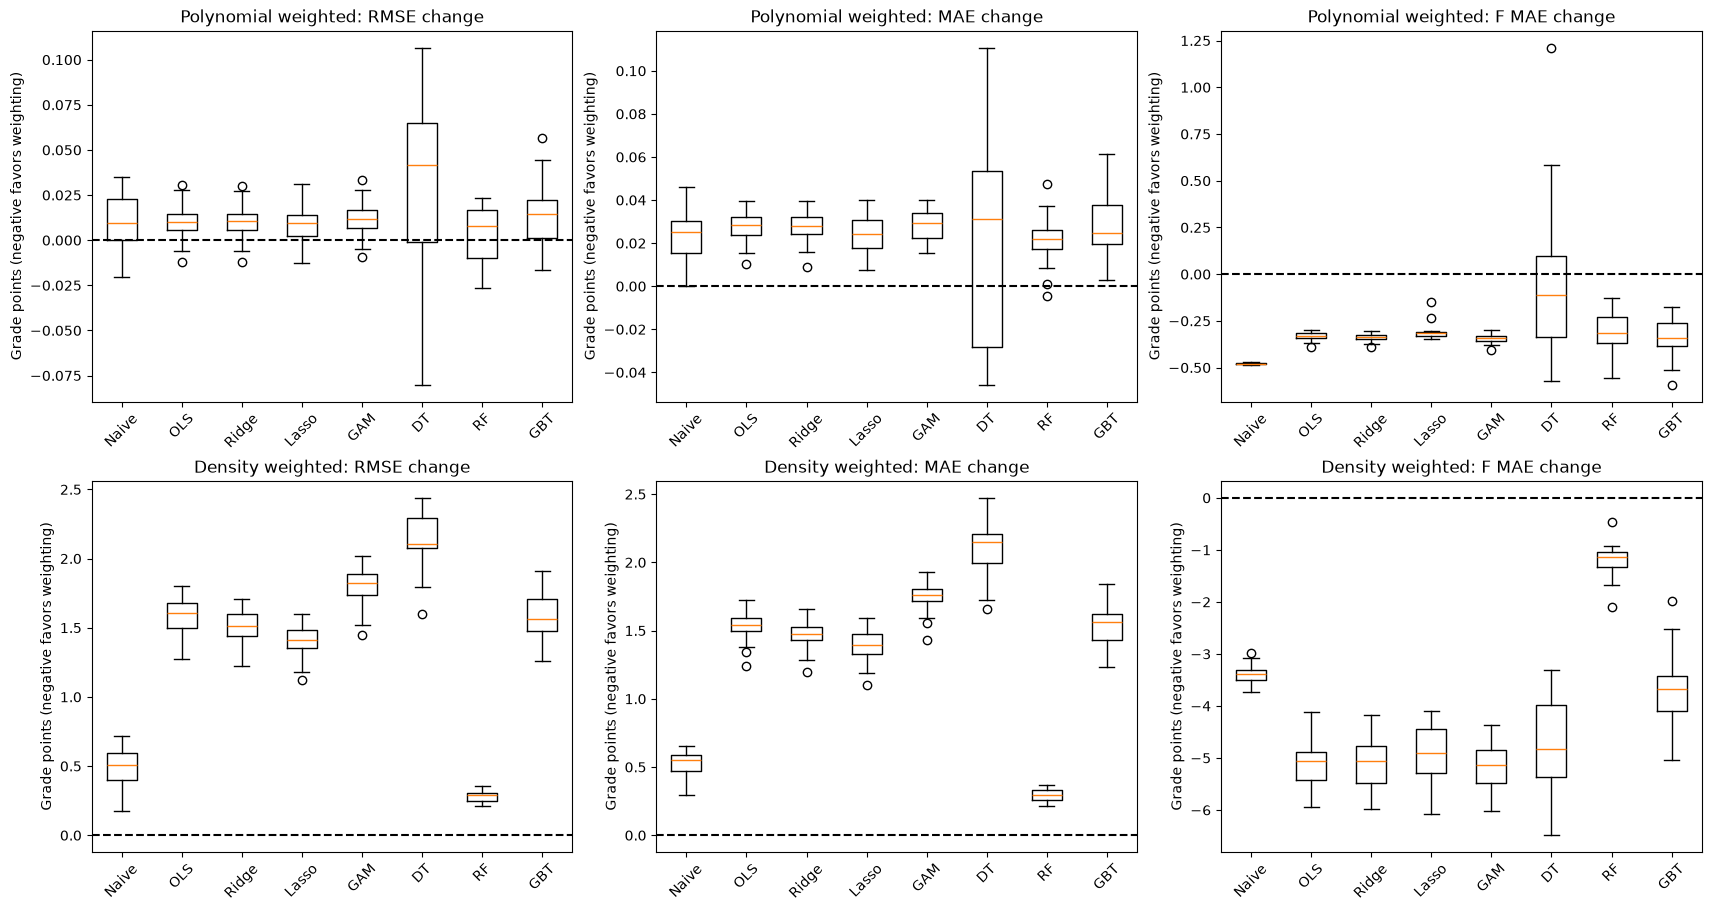

### Findings: λ=1.0, p=-2.0

Polynomial weighting reduced mean overall RMSE for 0/8 models and F-band MAE for 8/8 models across 20 splits.

| Model | Baseline RMSE | Polynomial RMSE | Density RMSE | Baseline F MAE | Polynomial F MAE | Density F MAE |
|---|---:|---:|---:|---:|---:|---:|
| Naive | 11.635 | 11.645 | 12.118 | 37.739 | 37.261 | 34.356 |
| OLS | 9.533 | 9.543 | 11.109 | 35.822 | 35.488 | 30.740 |
| Ridge | 9.531 | 9.541 | 11.033 | 35.849 | 35.511 | 30.792 |
| Lasso | 9.529 | 9.537 | 10.933 | 35.884 | 35.575 | 30.948 |
| GAM | 9.539 | 9.550 | 11.326 | 35.817 | 35.471 | 30.633 |
| DT | 10.013 | 10.044 | 12.146 | 36.151 | 36.110 | 31.399 |
| RF | 9.695 | 9.699 | 9.974 | 36.121 | 35.814 | 34.908 |
| GBT | 9.628 | 9.641 | 11.202 | 36.078 | 35.742 | 32.376 |

The formula weights high grades more when p > 0 and low grades more when p < 0. Judge this fixed setting by both overall performance and low-grade errors; these are exploratory comparisons on reused test splits.

In [4]:
fig, axes = plt.subplots(2,3,figsize=(17,9),layout='constrained')
paired_rows = []
for row, condition in enumerate(CONDITIONS[1:]):
    for ax, metric in zip(axes[row],['RMSE','MAE','F MAE']):
        pairs = comparison.pivot(index=['experiment','model'],columns='condition',values=metric)
        delta = (pairs[condition]-pairs['Baseline']).unstack('model').reindex(columns=NAMES)
        ax.boxplot([delta[name].dropna() for name in NAMES],tick_labels=NAMES)
        ax.axhline(0,color='black',ls='--'); ax.tick_params(axis='x',rotation=45)
        ax.set(title=f'{condition}: {metric} change',ylabel='Grade points (negative favors weighting)')
        for experiment, values in delta.iterrows():
            for name, value in values.items():
                paired_rows.append(dict(experiment=experiment,model=name,condition=condition,metric=metric,change=value))
fig.savefig(result_directory/'paired-changes.png',dpi=150)
plt.show()
paired_changes = pd.DataFrame(paired_rows)
paired_changes.to_csv(result_directory/'paired-changes.csv',index=False)
means = comparison.groupby(['model','condition'])[['RMSE','F MAE']].mean()
changes = paired_changes[paired_changes.condition.eq('Polynomial weighted')].groupby(['model','metric']).change.mean().unstack('metric')
lines = [f'### Findings: λ={WEIGHT_CONFIG["lam"]}, p={WEIGHT_CONFIG["power"]}', '',
    f'Polynomial weighting reduced mean overall RMSE for {int((changes.RMSE < 0).sum())}/{len(NAMES)} models and F-band MAE for {int((changes["F MAE"] < 0).sum())}/{len(NAMES)} models across {NUMBER_OF_EXPERIMENTS} splits.', '',
    '| Model | Baseline RMSE | Polynomial RMSE | Density RMSE | Baseline F MAE | Polynomial F MAE | Density F MAE |',
    '|---|---:|---:|---:|---:|---:|---:|']
for name in NAMES:
    b,p,d = [means.loc[(name,condition)] for condition in CONDITIONS]
    lines.append(f'| {name} | {b.RMSE:.3f} | {p.RMSE:.3f} | {d.RMSE:.3f} | {b["F MAE"]:.3f} | {p["F MAE"]:.3f} | {d["F MAE"]:.3f} |')
lines += ['', 'The formula weights high grades more when p > 0 and low grades more when p < 0. Judge this fixed setting by both overall performance and low-grade errors; these are exploratory comparisons on reused test splits.']
display(Markdown('\n'.join(lines)))

## Error by actual grade band
Every held-out student receives equal weight in these MAE calculations. The table also reports the number of F-band students per split in the saved comparison file.

grade band                      A       B      C       D       F
model condition                                                 
DT    Baseline             16.401   9.150  4.804   8.809  36.151
      Density weighted     15.027  12.771  9.051   5.442  31.399
      Polynomial weighted  17.345   9.477  4.750   8.634  36.110
GAM   Baseline             14.861   8.469  4.573   8.168  35.817
      Density weighted     13.334  11.412  7.999   5.808  30.633
      Polynomial weighted  15.277   8.794  4.589   7.937  35.471
GBT   Baseline             15.421   8.738  4.490   8.404  36.078
      Density weighted     14.548  11.157  7.824   5.730  32.376
      Polynomial weighted  15.783   9.059  4.522   8.147  35.742
Lasso Baseline             15.425   8.485  4.522   8.198  35.884
      Density weighted     14.429  10.679  7.400   6.178  30.948
      Polynomial weighted  15.906   8.826  4.527   7.949  35.575
Naive Baseline             26.884  13.353  3.545  13.079  37.739
      Density weighted     30.266  16.736  4.619   9.697  34.356
      Polynomial weighted  27.361  13.831  3.598  12.601  37.261
OLS   Baseline             15.078   8.414  4.606   8.134  35.822
      Density weighted     14.163  10.713  7.564   6.447  30.740
      Polynomial weighted  15.519   8.739  4.623   7.893  35.488
RF    Baseline             16.268   8.784  4.543   8.429  36.121
      Density weighted     14.637   9.420  5.532   7.116  34.908
      Polynomial weighted  16.612   9.054  4.570   8.201  35.814
Ridge Baseline             15.173   8.438  4.577   8.153  35.849
      Density weighted     14.245  10.700  7.498   6.339  30.792
      Polynomial weighted  15.590   8.759  4.601   7.905  35.511

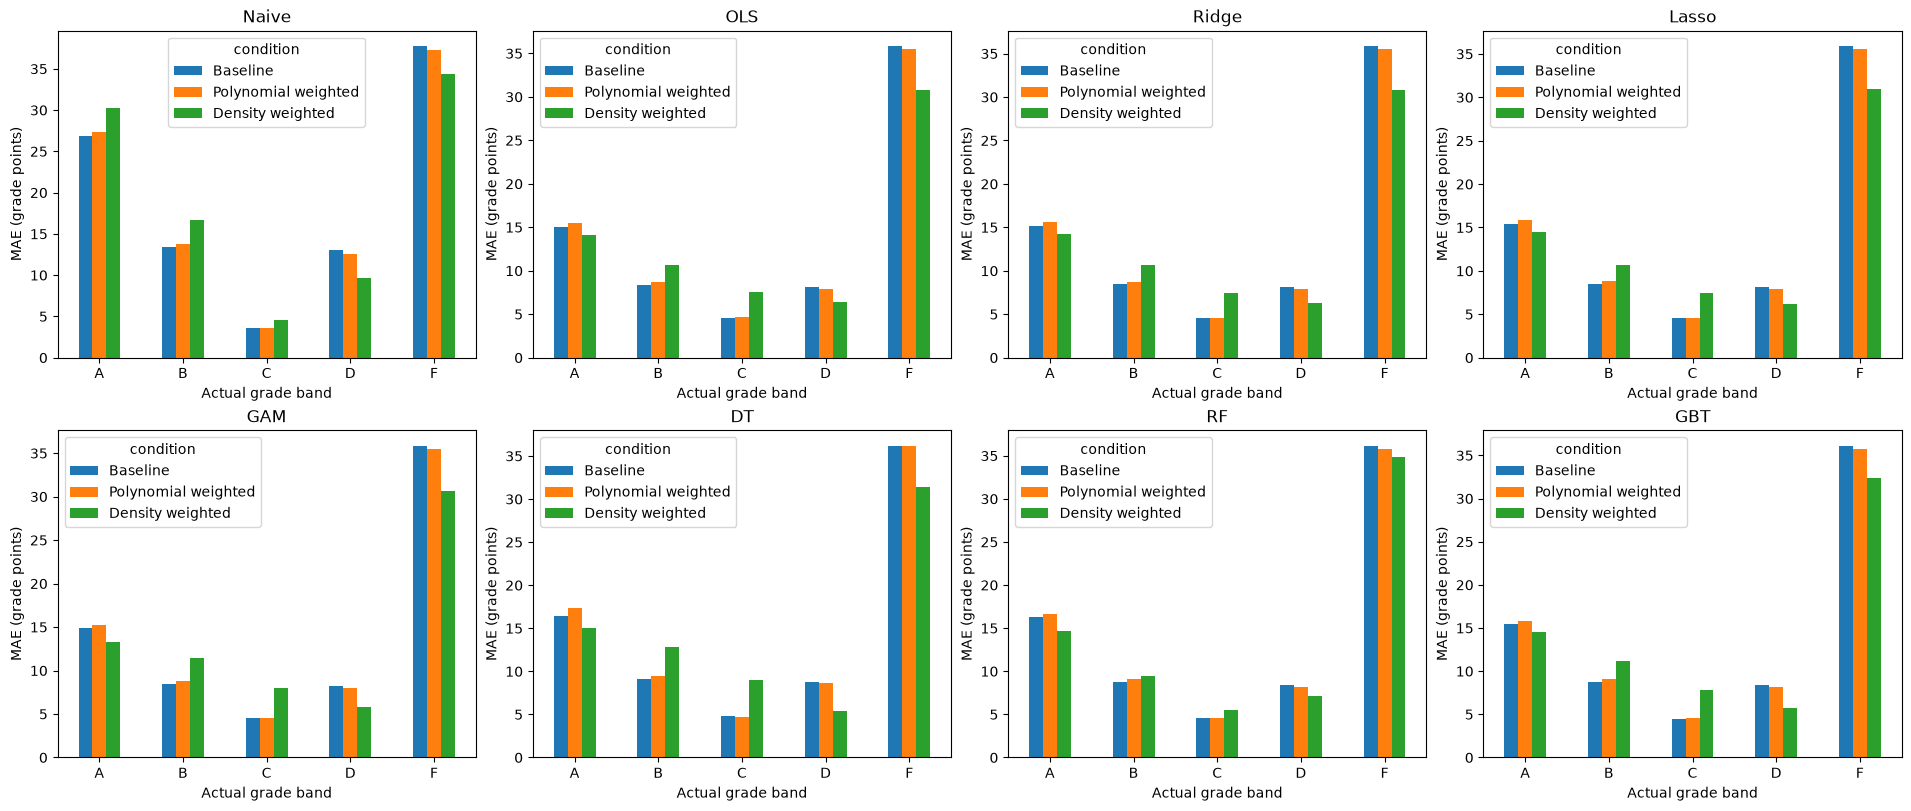

In [5]:
band_errors = (all_predictions.groupby(['experiment','model','condition','grade band'])['absolute error']
    .mean().rename('MAE').reset_index())
band_errors.to_csv(result_directory/'grade-band-errors.csv',index=False)
display(band_errors.groupby(['model','condition','grade band']).MAE.mean().unstack('grade band').round(3))
fig, axes = plt.subplots(2,4,figsize=(19,8),layout='constrained')
for ax,name in zip(axes.flat,NAMES):
    summary = band_errors[band_errors.model.eq(name)].groupby(['grade band','condition']).MAE.mean().unstack('condition')
    summary.reindex(columns=CONDITIONS).plot.bar(ax=ax,rot=0)
    ax.set(title=name,xlabel='Actual grade band',ylabel='MAE (grade points)')
fig.savefig(result_directory/'grade-band-errors.png',dpi=150)
plt.show()

## Predicted versus actual grades
Split 0 is shown for all eight models. The x-axis is the **actual final grade**, and the y-axis is its prediction. Red points mark the F band; the dashed line denotes a perfect prediction. Shared axes are expanded if any prediction falls outside 0–100.

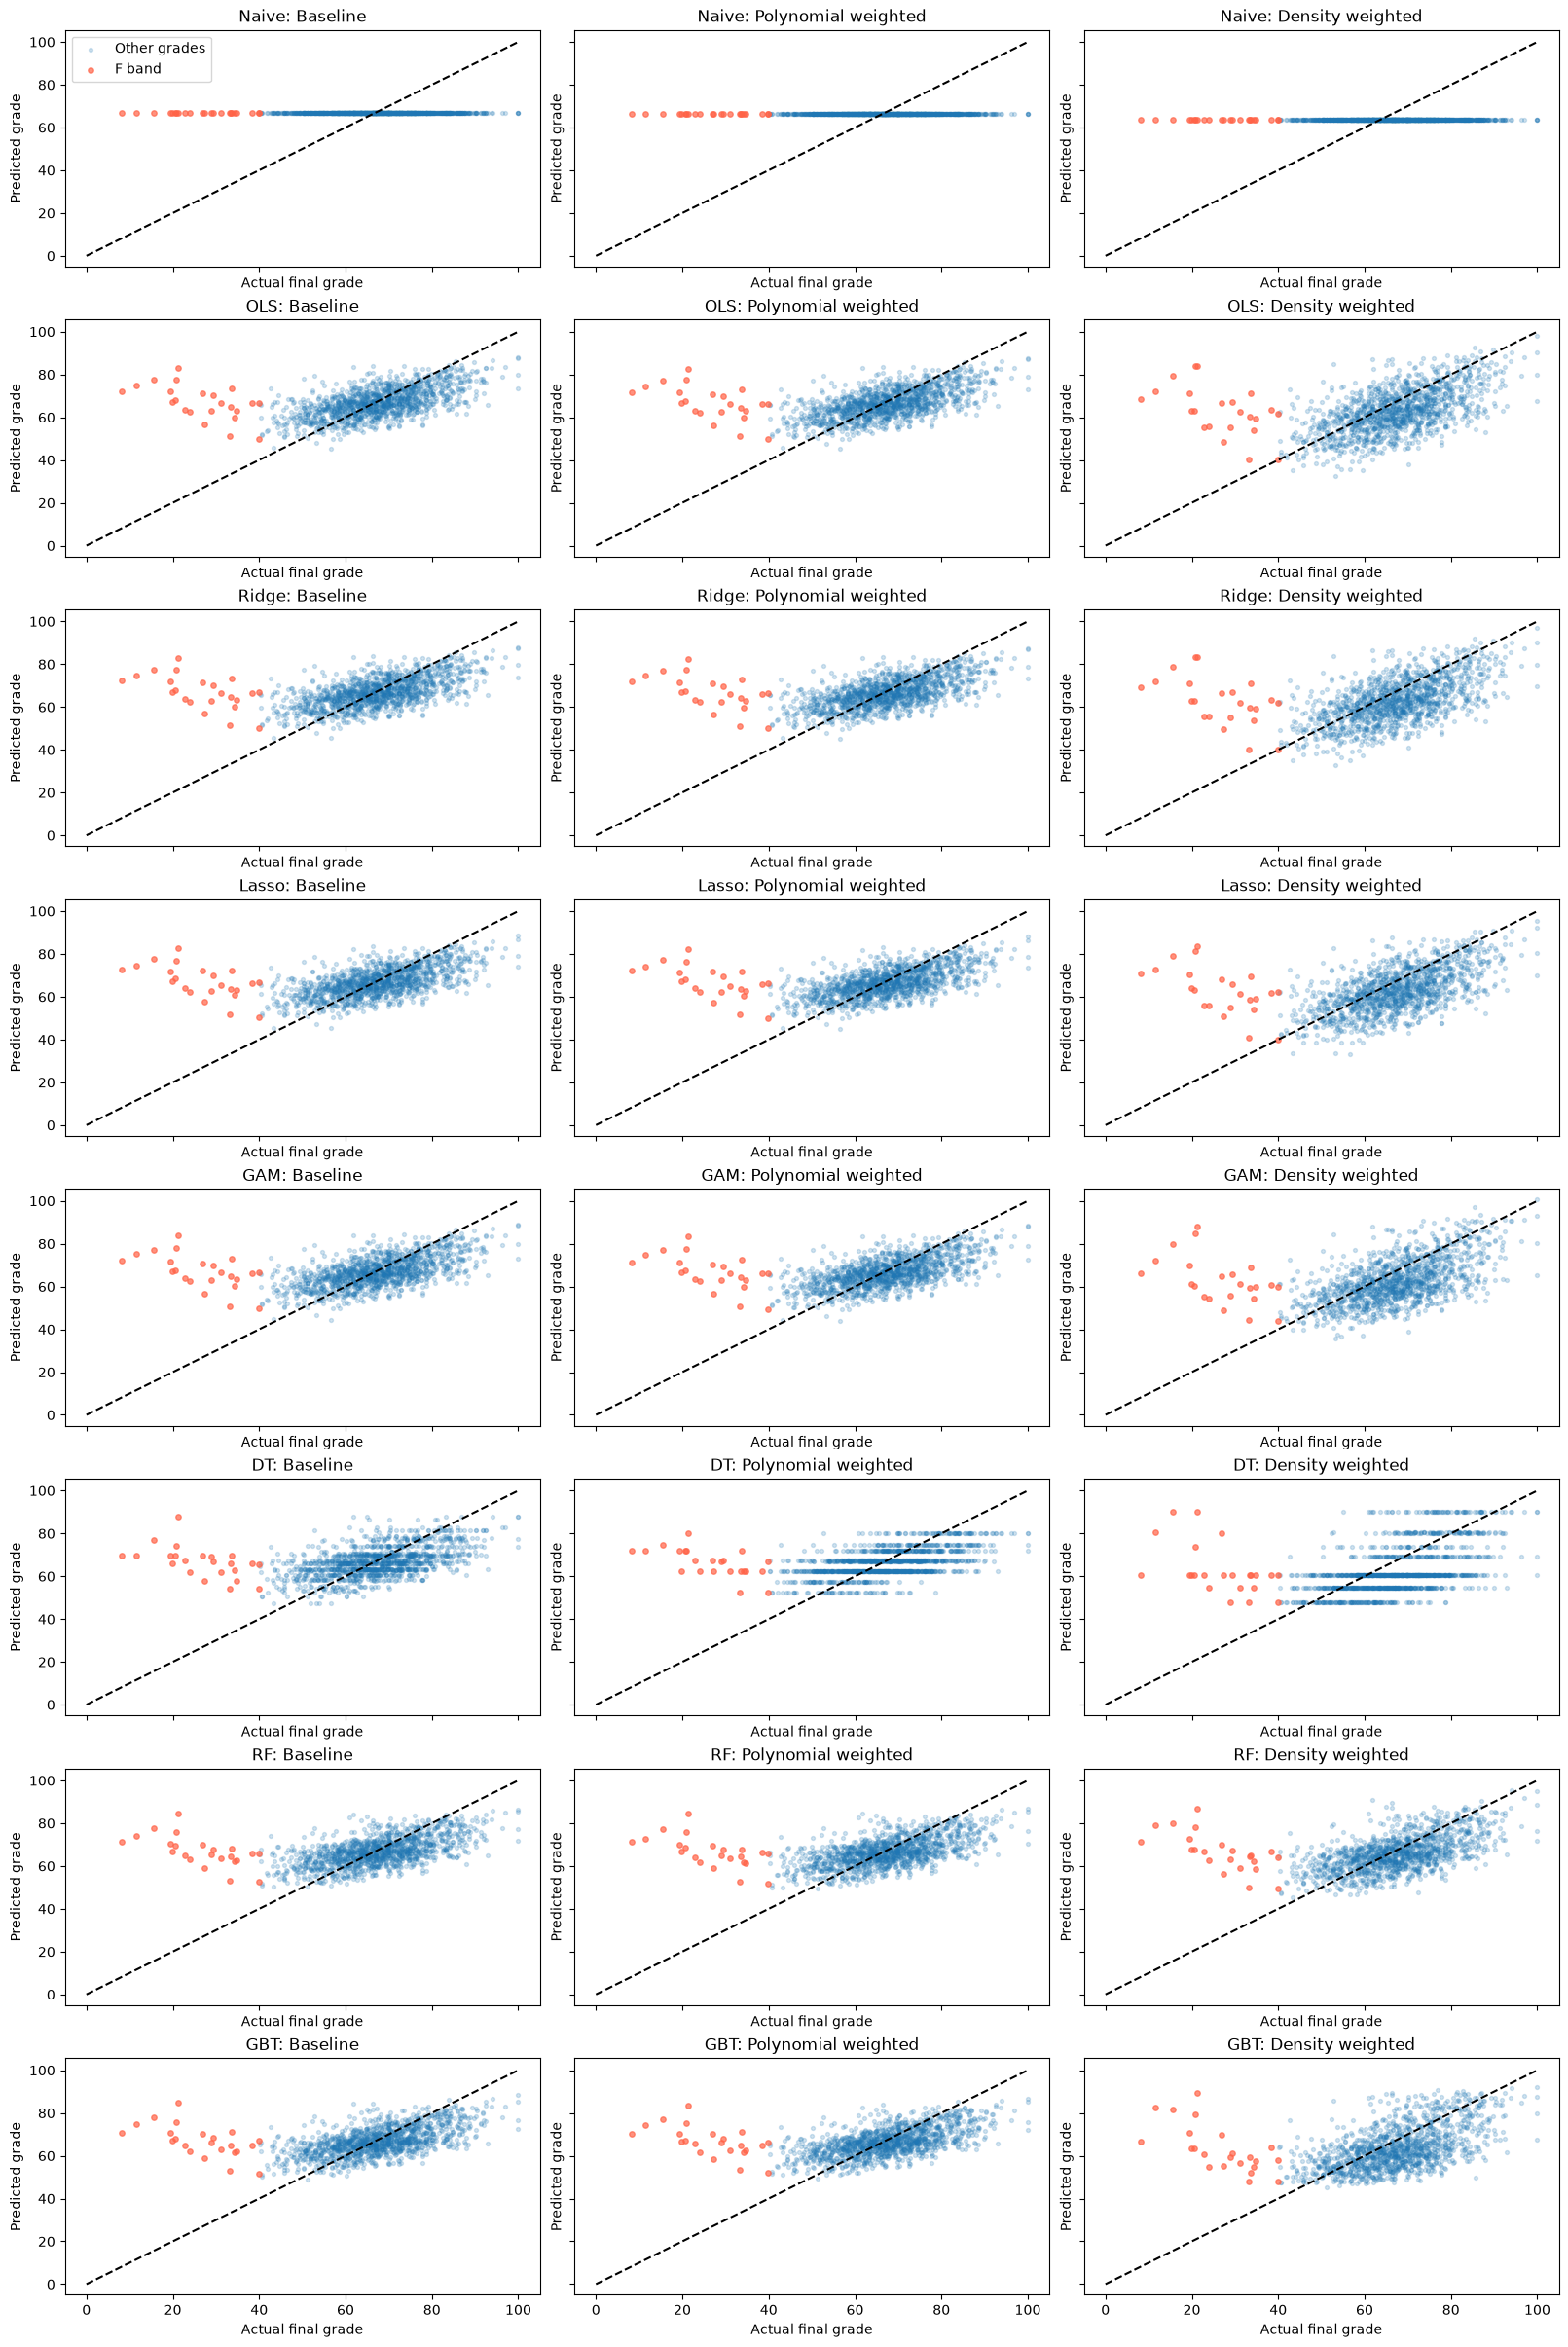

In [6]:
fig, axes = plt.subplots(len(NAMES),len(CONDITIONS),figsize=(16,3*len(NAMES)),layout='constrained',sharex=True,sharey=True)
for row,name in enumerate(NAMES):
    for col,condition in enumerate(CONDITIONS):
        p = all_predictions[(all_predictions.experiment == 0) & all_predictions.model.eq(name) & all_predictions.condition.eq(condition)]
        low = p['grade band'].eq('F'); ax = axes[row,col]
        ax.scatter(p.loc[~low,'actual'],p.loc[~low,'predicted'],s=8,alpha=.2,label='Other grades')
        ax.scatter(p.loc[low,'actual'],p.loc[low,'predicted'],s=15,alpha=.7,color='tomato',label='F band')
        ax.plot([0,100],[0,100],'--',color='black')
        ax.set(title=f'{name}: {condition}',xlabel='Actual final grade',ylabel='Predicted grade')
axes[0,0].legend()
fig.savefig(result_directory/'predicted-actual.png',dpi=130)
plt.show()